# Student Performance Prediction System

## Day 03 – Exploratory Data Analysis

### Objective
To explore the cleaned student dataset, identify
patterns, understand feature distributions, and
analyse relationships between student characteristics
and academic performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load cleaned dataset
df = pd.read_csv(
    "../dataset/student_performance_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (38000, 7)


In [2]:
numerical_columns = [
    "Study Hours per Week",
    "Attendance Rate",
    "Previous Grades"
]

df[numerical_columns].describe()

,Study Hours per Week,Attendance Rate,Previous Grades
count,35197.000000,32169.000000,35660.000000
mean,10.266125,70.954145,64.672925
std,4.712734,16.820118,14.509373
min,0.000000,0.500000,8.300000
25%,6.900000,59.700000,54.900000
50%,10.100000,72.400000,64.900000
75%,13.500000,83.900000,74.700000
max,32.400000,100.000000,100.000000


In [3]:
print(df["Passed"].value_counts())

print("\nPercentage distribution:")
print(df["Passed"].value_counts(normalize=True) * 100)

Passed
Yes    19011
No     18989
Name: count, dtype: int64

Percentage distribution:
Passed
Yes    50.028947
No     49.971053
Name: proportion, dtype: float64


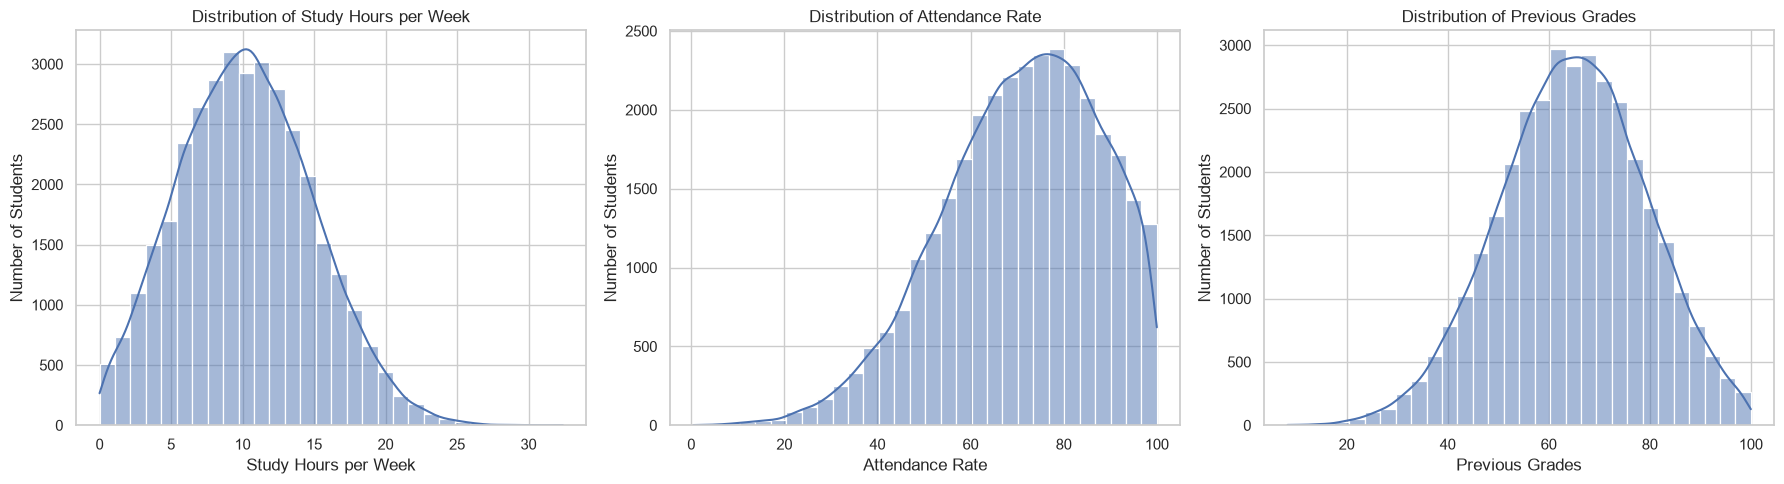

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, numerical_columns):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.savefig(
    "../visualizations/numerical_distributions.png",
    dpi=300
)
plt.show()

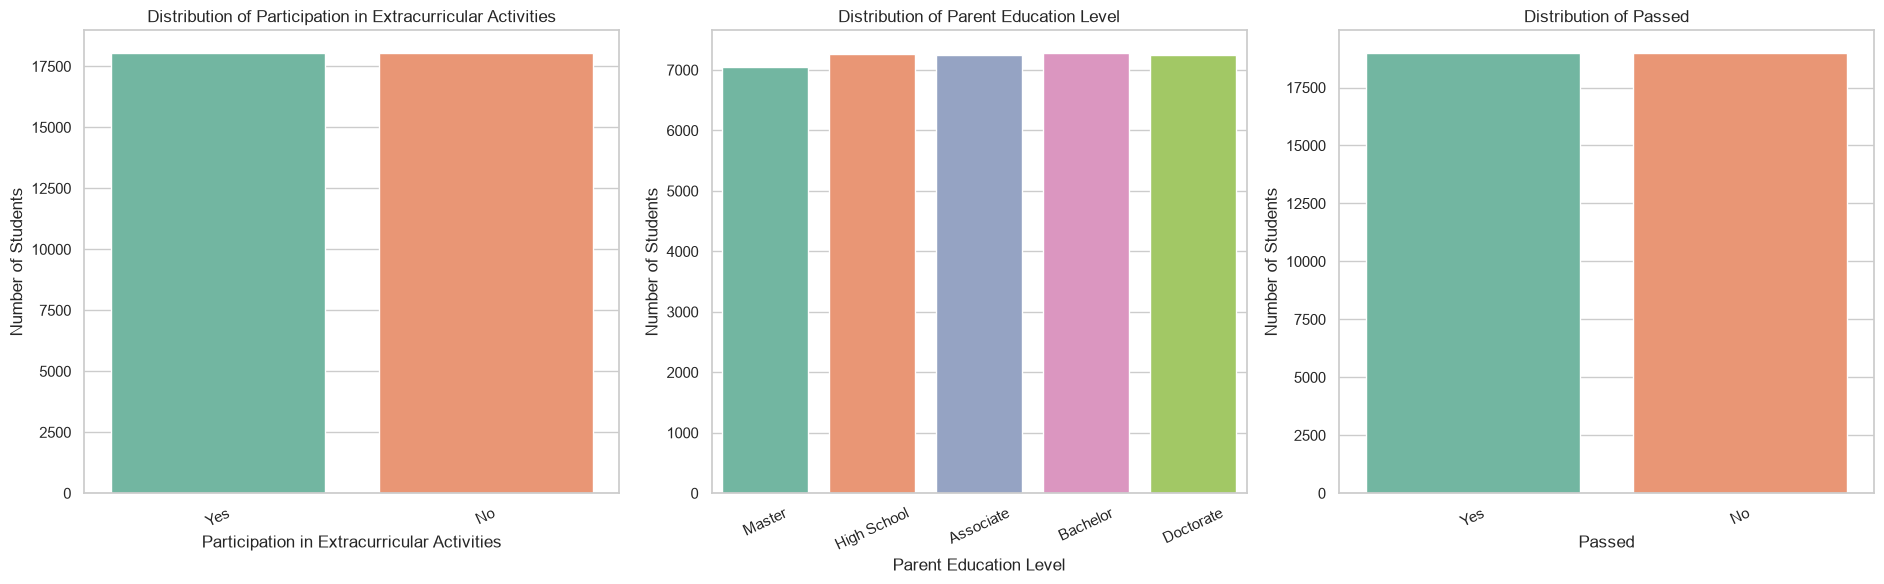

In [5]:
categorical_columns = [
    "Participation in Extracurricular Activities",
    "Parent Education Level",
    "Passed"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, col in zip(axes, categorical_columns):

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Students")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

plt.savefig(
    "../visualizations/categorical_distributions.png",
    dpi=300
)

plt.show()

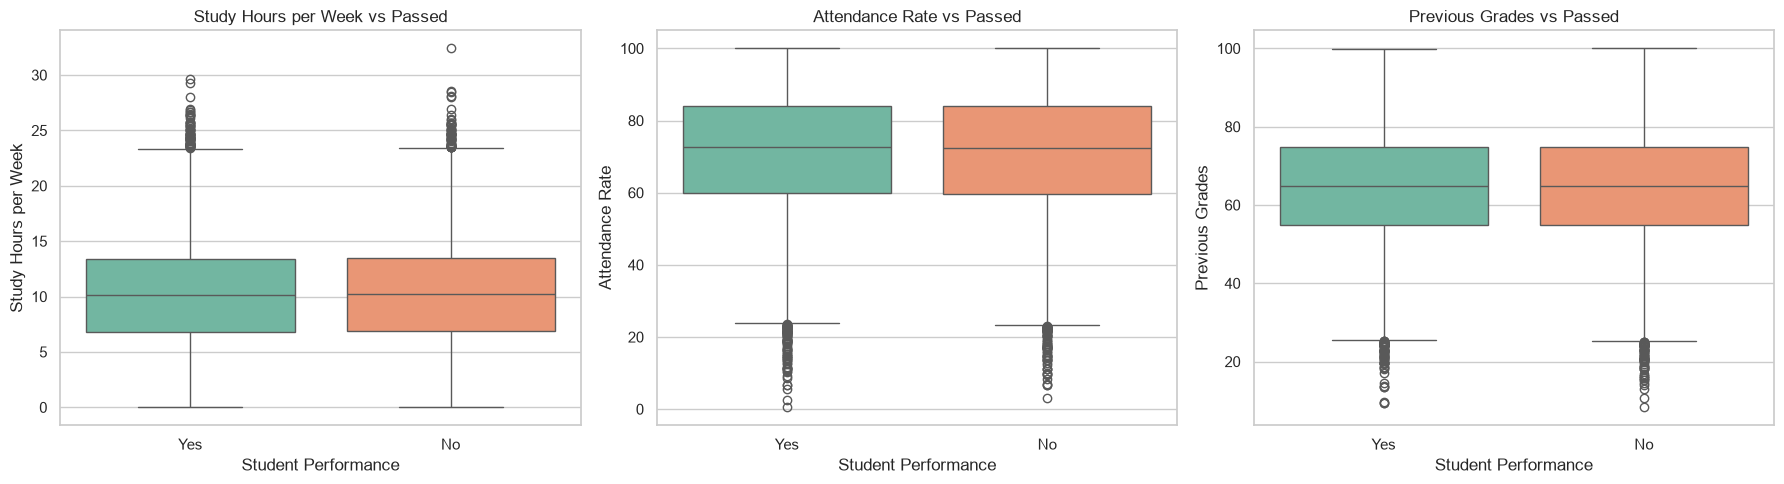

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, numerical_columns):

    sns.boxplot(
        data=df,
        x="Passed",
        y=col,
        hue="Passed",
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col} vs Passed")
    ax.set_xlabel("Student Performance")
    ax.set_ylabel(col)

plt.tight_layout()

plt.savefig(
    "../visualizations/performance_boxplots.png",
    dpi=300
)

plt.show()

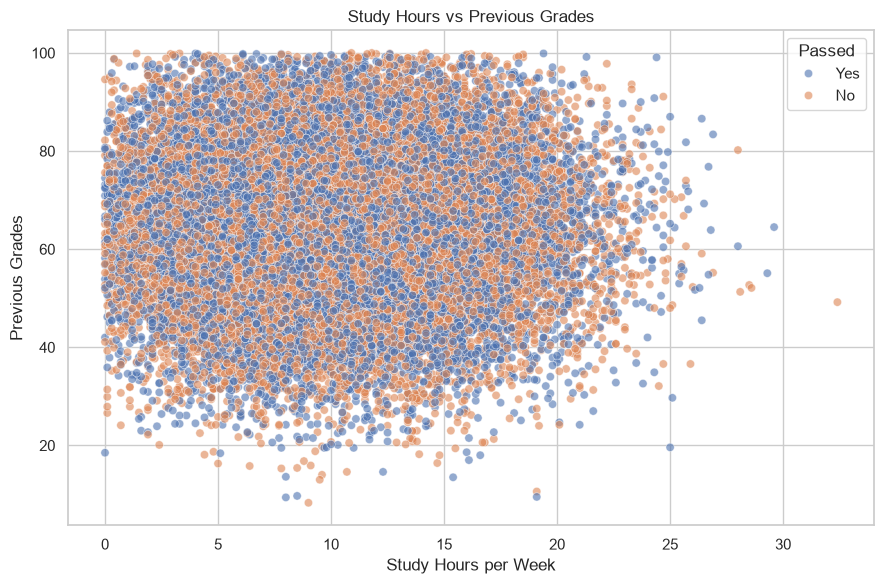

In [7]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Study Hours per Week",
    y="Previous Grades",
    hue="Passed",
    alpha=0.6
)

plt.title("Study Hours vs Previous Grades")
plt.xlabel("Study Hours per Week")
plt.ylabel("Previous Grades")

plt.tight_layout()

plt.savefig(
    "../visualizations/study_hours_vs_grades.png",
    dpi=300
)

plt.show()

In [8]:
correlation_matrix = df[
    numerical_columns
].corr()

print(correlation_matrix)

                      Study Hours per Week  Attendance Rate  Previous Grades
Study Hours per Week              1.000000         0.001594         0.003244
Attendance Rate                   0.001594         1.000000        -0.003345
Previous Grades                   0.003244        -0.003345         1.000000


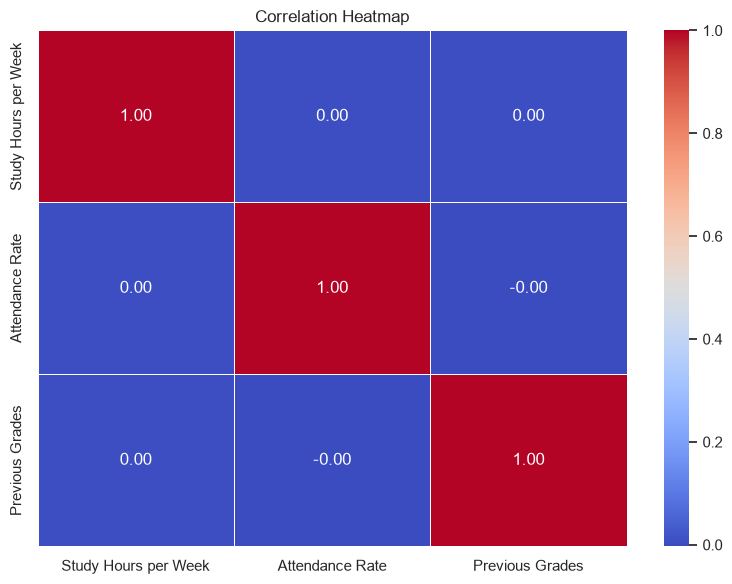

In [9]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "../visualizations/correlation_heatmap.png",
    dpi=300
)

plt.show()

In [10]:
activity_analysis = pd.crosstab(
    df["Participation in Extracurricular Activities"],
    df["Passed"],
    normalize="index"
) * 100

display(activity_analysis)

Passed,No,Yes
Participation in Extracurricular Activities,,
No,50.099635,49.900365
Yes,49.961180,50.038820


In [11]:
parent_analysis = pd.crosstab(
    df["Parent Education Level"],
    df["Passed"],
    normalize="index"
) * 100

display(parent_analysis)

Passed,No,Yes
Parent Education Level,,
Associate,50.766469,49.233531
Bachelor,49.849108,50.150892
Doctorate,49.200000,50.800000
High School,49.848568,50.151432
Master,50.304662,49.695338


In [12]:
performance_means = df.groupby("Passed")[
    numerical_columns
].mean()

display(performance_means)

,Study Hours per Week,Attendance Rate,Previous Grades
Passed,,,
No,10.324274,70.923625,64.662178
Yes,10.208190,70.985023,64.683663


In [13]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

X = df[
    numerical_columns
]

y = df["Passed"].map({
    "No": 0,
    "Yes": 1
})

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

mi_scores = mutual_info_classif(
    X_imputed,
    y,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": numerical_columns,
    "Mutual Information": mi_scores
}).sort_values(
    by="Mutual Information",
    ascending=False
)

display(mi_results)

,Feature,Mutual Information
1,Attendance Rate,0.000816
0,Study Hours per Week,0.000000
2,Previous Grades,0.000000


In [14]:
from scipy.stats import chi2_contingency

categorical_features = [
    "Participation in Extracurricular Activities",
    "Parent Education Level"
]

for col in categorical_features:

    table = pd.crosstab(
        df[col],
        df["Passed"]
    )

    chi2, p_value, dof, expected = chi2_contingency(table)

    print("\nFeature:", col)
    print("Chi-square:", chi2)
    print("P-value:", p_value)


Feature: Participation in Extracurricular Activities
Chi-square: 0.06377123594491284
P-value: 0.8006316810900526

Feature: Parent Education Level
Chi-square: 3.9515951190167407
P-value: 0.41259637290502416


## Advanced Statistical Analysis

### 1. Group Average Comparison

The average study hours, attendance rates and previous grades were compared between students who passed and failed.

The results showed very small differences between the two groups.

### 2. Mutual Information Analysis

Mutual Information was calculated to estimate the dependency between numerical features and the target variable.

Results:
- Attendance Rate: 0.000816
- Study Hours per Week: 0.000000
- Previous Grades: 0.000000

The scores indicate very weak estimated predictive information.

### 3. Chi-Square Test

Chi-square tests were performed to investigate associations between categorical features and the target variable.

Results:
- Extracurricular Activities: p-value = 0.8006
- Parent Education Level: p-value = 0.4126

Both p-values are greater than the 0.05 significance level. Therefore, no statistically significant association was detected.

### 4. Overall Conclusion

The statistical analysis indicates that the selected input features have very weak relationships with the target variable.

This raises concerns about the predictive suitability of the dataset.

Further investigation through baseline machine learning experiments is required before making a final decision about dataset suitability.